In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [2]:
df = pd.read_csv("expenses.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")

df = df.dropna(subset=["Date", "Amount", "Category"])
df = df[df["Amount"] > 0]
df["Category"] = df["Category"].astype(str).str.strip()
df["Description"] = df["Description"].fillna("No description")

print("Number of expense records:", len(df))
display(df)

Number of expense records: 121


,Date,Amount,Category,Description
0,2025-01-02,1588.95,Healthcare,Doctor Visit
1,2025-01-06,1325.23,Healthcare,Health Checkup
2,2025-01-08,836.68,Food,Groceries
3,2025-01-20,553.05,Food,Breakfast
4,2025-01-23,326.86,Food,Groceries
...,...,...,...,...
116,2025-12-10,610.00,Healthcare,Doctor Visit
117,2025-12-10,267.67,Transport,Bus Fare
118,2025-12-12,294.57,Transport,Auto Ride
119,2025-12-13,1616.71,Healthcare,Medicine


In [3]:
display(df.head())
print("Rows and columns:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nCategories:")
print(sorted(df["Category"].unique()))

,Date,Amount,Category,Description
0,2025-01-02,1588.95,Healthcare,Doctor Visit
1,2025-01-06,1325.23,Healthcare,Health Checkup
2,2025-01-08,836.68,Food,Groceries
3,2025-01-20,553.05,Food,Breakfast
4,2025-01-23,326.86,Food,Groceries


Rows and columns: (121, 4)

Missing values:
Date           0
Amount         0
Category       0
Description    0
dtype: int64

Categories:
['Entertainment', 'Food', 'Healthcare', 'Shopping', 'Transport', 'Utilities']


In [4]:
class ExpenseTracker:
    def __init__(self, data):
        self.data = data.copy()

    def add_expense(self, date, amount, category, description):
        # Check the values before adding a new expense
        try:
            amount = float(amount)
            pd.to_datetime(date, errors="raise")
        except (ValueError, TypeError):
            print("Please enter a valid date and amount.")
            return

        if amount <= 0:
            print("Amount must be greater than zero.")
            return

        category = str(category).strip()
        if category not in self.data["Category"].unique():
            print("Please use a valid category.")
            return

        new_row = {
            "Date": pd.to_datetime(date),
            "Amount": amount,
            "Category": category,
            "Description": str(description).strip()
        }
        self.data = pd.concat([self.data, pd.DataFrame([new_row])], ignore_index=True)
        print("Expense added successfully.")

    def get_summary(self):
        total = self.data["Amount"].sum()
        average = self.data["Amount"].mean()
        print(f"Total spending: ₹{total:.2f}")
        print(f"Average expense: ₹{average:.2f}")
        return total, average

    def filter_expenses(self, category=None, start_date=None, end_date=None,
                        min_amount=None, max_amount=None):
        result = self.data.copy()

        if category:
            result = result[result["Category"].str.lower() == category.lower()]
        if start_date:
            result = result[result["Date"] >= pd.to_datetime(start_date)]
        if end_date:
            result = result[result["Date"] <= pd.to_datetime(end_date)]
        if min_amount is not None:
            result = result[result["Amount"] >= float(min_amount)]
        if max_amount is not None:
            result = result[result["Amount"] <= float(max_amount)]

        return result

    def generate_report(self):
        if self.data.empty:
            print("No expenses to report.")
            return

        total = self.data["Amount"].sum()
        average = self.data["Amount"].mean()
        print("EXPENSE REPORT")
        print("-" * 30)
        print("Number of records:", len(self.data))
        print(f"Total spending: ₹{total:.2f}")
        print(f"Average expense: ₹{average:.2f}")
        print("\nSpending by category:")
        print(self.data.groupby("Category")["Amount"].sum().sort_values(ascending=False))


In [6]:
tracker = ExpenseTracker(df)
tracker.get_summary()

Total spending: ₹95929.44
Average expense: ₹792.81


(np.float64(95929.44), np.float64(792.8052892561984))

In [7]:
tracker.generate_report()

EXPENSE REPORT
------------------------------
Number of records: 121
Total spending: ₹95929.44
Average expense: ₹792.81

Spending by category:
Category
Healthcare       22835.55
Utilities        20882.11
Shopping         19901.15
Food             12732.53
Entertainment    10956.01
Transport         8622.09
Name: Amount, dtype: float64


In [17]:
# Add a new expense

date = input("Enter date (YYYY-MM-DD): ")
amount = input("Enter amount: ")
category = input("Enter category: ")
description = input("Enter description: ")

tracker.add_expense(date, amount, category, description)

tracker.data.to_csv("expenses.csv", index=False)

print("Total records:", len(tracker.data))

Enter date (YYYY-MM-DD):  2026-10-24
Enter amount:  265
Enter category:  Food
Enter description:  Snacks


Expense added successfully.
Total records: 123


In [18]:
# show Food expenses
food_expenses = tracker.filter_expenses(category="Food")
display(food_expenses)

# expenses of ₹500 or more
high_expenses = tracker.filter_expenses(min_amount=500)
display(high_expenses)

# expenses within a date range
date_expenses = tracker.filter_expenses(
    start_date="2026-03-01",
    end_date="2026-06-30"
)
display(date_expenses)


,Date,Amount,Category,Description,Month
2,2025-01-08,836.68,Food,Groceries,2025-01
3,2025-01-20,553.05,Food,Breakfast,2025-01
4,2025-01-23,326.86,Food,Groceries,2025-01
6,2025-02-05,608.69,Food,Breakfast,2025-02
9,2025-02-07,434.13,Food,Snacks,2025-02
15,2025-02-18,606.73,Food,Breakfast,2025-02
16,2025-02-20,600.84,Food,Snacks,2025-02
17,2025-02-20,386.25,Food,Breakfast,2025-02
18,2025-02-21,502.37,Food,Snacks,2025-02
19,2025-02-22,366.74,Food,Breakfast,2025-02


,Date,Amount,Category,Description,Month
0,2025-01-02,1588.95,Healthcare,Doctor Visit,2025-01
1,2025-01-06,1325.23,Healthcare,Health Checkup,2025-01
2,2025-01-08,836.68,Food,Groceries,2025-01
3,2025-01-20,553.05,Food,Breakfast,2025-01
5,2025-01-28,1210.87,Healthcare,Health Checkup,2025-01
...,...,...,...,...,...
113,2025-11-24,1046.81,Healthcare,Health Checkup,2025-11
114,2025-11-29,1048.11,Utilities,Internet Bill,2025-11
115,2025-12-09,1478.27,Healthcare,Doctor Visit,2025-12
116,2025-12-10,610.00,Healthcare,Doctor Visit,2025-12


,Date,Amount,Category,Description,Month


In [19]:
amounts = tracker.data["Amount"].to_numpy()

print("Total using NumPy: ₹", round(np.sum(amounts), 2))
print("Average using NumPy: ₹", round(np.mean(amounts), 2))
print("Highest expense: ₹", round(np.max(amounts), 2))
print("Lowest expense: ₹", round(np.min(amounts), 2))

category_total = tracker.data.groupby("Category")["Amount"].sum()
all_total = category_total.sum()
category_percent = (category_total / all_total) * 100

summary_table = pd.DataFrame({
    "Total Amount": category_total,
    "Spending Percentage": category_percent.round(2)
}).sort_values("Total Amount", ascending=False)

display(summary_table)


Total using NumPy: ₹ 96444.44
Average using NumPy: ₹ 784.1
Highest expense: ₹ 2762.0
Lowest expense: ₹ 24.89


,Total Amount,Spending Percentage
Category,,
Healthcare,22835.55,23.68
Utilities,20882.11,21.65
Shopping,19901.15,20.63
Food,13247.53,13.74
Entertainment,10956.01,11.36
Transport,8622.09,8.94


In [20]:
tracker.data["Month"] = tracker.data["Date"].dt.to_period("M").astype(str)

monthly_total = tracker.data.groupby("Month")["Amount"].sum()
monthly_average = tracker.data.groupby("Month")["Amount"].mean()

print("Monthly total spending:")
display(monthly_total.to_frame("Total Amount"))

print("Monthly average spending:")
display(monthly_average.to_frame("Average Amount"))

print("Highest spending category:", category_total.idxmax())
print("Highest spending month:", monthly_total.idxmax())


Monthly total spending:


,Total Amount
Month,
2025-01,5841.64
2025-02,12063.95
2025-03,8015.52
2025-04,7898.11
2025-05,9116.67
2025-06,11574.51
2025-07,5376.43
2025-08,4959.97
2025-09,5889.02


Monthly average spending:


,Average Amount
Month,
2025-01,973.606667
2025-02,670.219444
2025-03,801.552000
2025-04,987.263750
2025-05,759.722500
2025-06,723.406875
2025-07,1344.107500
2025-08,619.996250
2025-09,736.127500


Highest spending category: Healthcare
Highest spending month: 2025-10


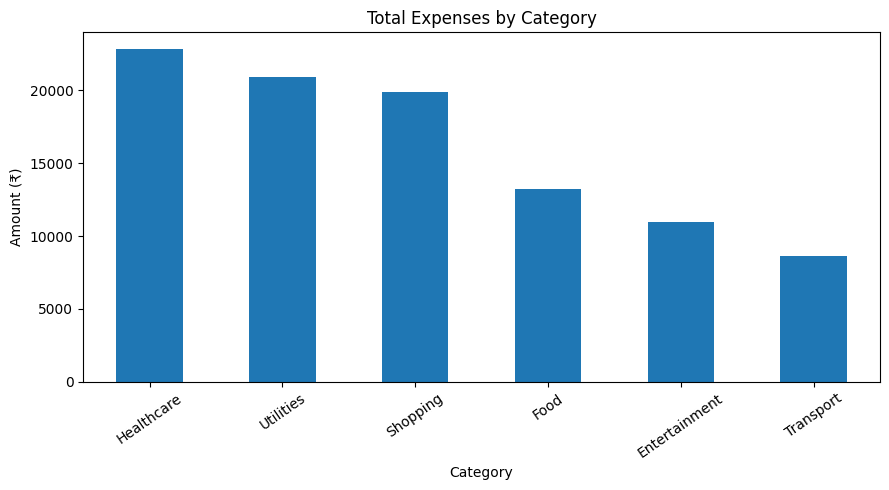

In [21]:
#Bar chart:

category_total.sort_values(ascending=False).plot(kind="bar", figsize=(9, 5))
plt.title("Total Expenses by Category")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


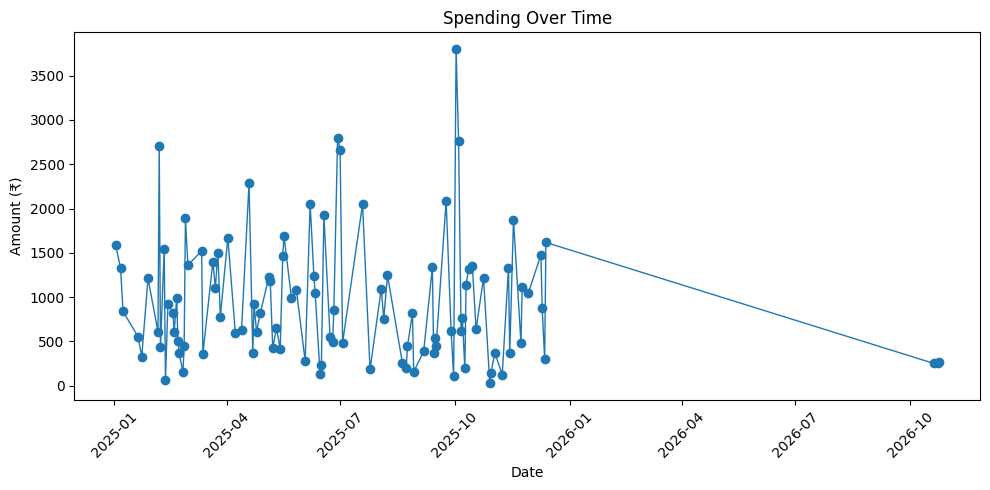

In [22]:
# Line graph: 

daily_total = tracker.data.groupby("Date")["Amount"].sum().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(daily_total.index, daily_total.values, marker="o", linewidth=1)
plt.title("Spending Over Time")
plt.xlabel("Date")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


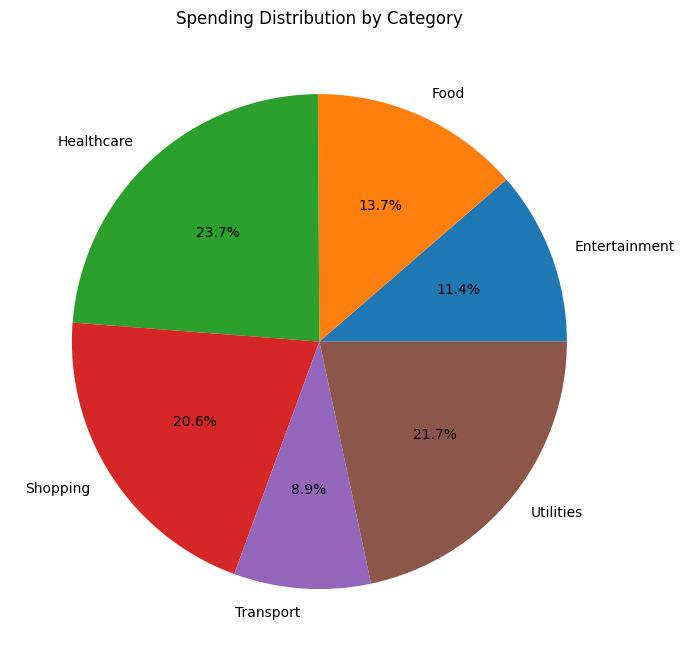

In [23]:
# Pie chart:

category_total.plot(kind="pie", autopct="%1.1f%%", figsize=(7, 7))
plt.title("Spending Distribution by Category")
plt.ylabel("")
plt.tight_layout()
plt.show()


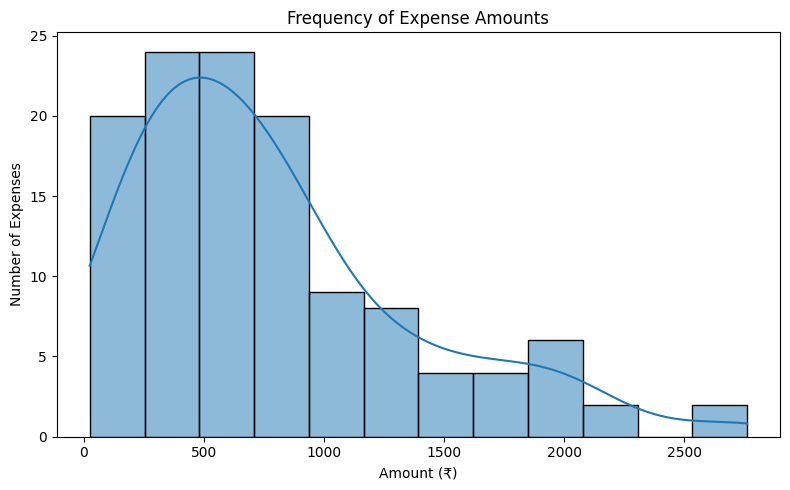

In [24]:
# Histogram:

plt.figure(figsize=(8, 5))
sns.histplot(data=tracker.data, x="Amount", bins=12, kde=True)
plt.title("Frequency of Expense Amounts")
plt.xlabel("Amount (₹)")
plt.ylabel("Number of Expenses")
plt.tight_layout()
plt.show()


In [25]:
tracker.data.drop(columns=["Month"], errors="ignore").to_csv("expenses.csv", index=False)

saved_data = pd.read_csv("expenses.csv")
print("Records saved in expenses.csv:", len(saved_data))
display(saved_data)


Records saved in expenses.csv: 123


,Date,Amount,Category,Description
0,2025-01-02,1588.95,Healthcare,Doctor Visit
1,2025-01-06,1325.23,Healthcare,Health Checkup
2,2025-01-08,836.68,Food,Groceries
3,2025-01-20,553.05,Food,Breakfast
4,2025-01-23,326.86,Food,Groceries
...,...,...,...,...
118,2025-12-12,294.57,Transport,Auto Ride
119,2025-12-13,1616.71,Healthcare,Medicine
120,2026-10-23,250.00,Food,Breakfast
121,2026-10-20,250.00,Food,Evening snacks
